In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import files

uploaded = files.upload()


Saving perf_training.csv to perf_training.csv


In [4]:
# Load the training dataset
train = pd.read_csv('/content/perf_training.csv')

# Display the first 5 rows
train.head()

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer


In [ ]:
train.shape

(2000, 22)

In [ ]:
train.columns.tolist()

['Employee_ID',
 'Age',
 'Gender',
 'City',
 'Education_Level',
 'Department',
 'Experience_Years',
 'Monthly_Salary',
 'Projects_Completed',
 'Training_Hours',
 'Certifications',
 'Work_Life_Balance',
 'Job_Satisfaction',
 'Manager_Rating',
 'Overtime_Hours',
 'Commute_Time_Min',
 'Laptop_Issue_Count',
 'Cafeteria_Rating',
 'Internet_Stability',
 'Last_Promotion_Years',
 'Absenteeism_Days',
 'Performance_Category']

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           2000 non-null   int64  
 1   Age                   1873 non-null   float64
 2   Gender                1934 non-null   object 
 3   City                  1789 non-null   object 
 4   Education_Level       1806 non-null   object 
 5   Department            1801 non-null   object 
 6   Experience_Years      1747 non-null   float64
 7   Monthly_Salary        1895 non-null   float64
 8   Projects_Completed    1712 non-null   float64
 9   Training_Hours        1702 non-null   float64
 10  Certifications        1695 non-null   float64
 11  Work_Life_Balance     1819 non-null   float64
 12  Job_Satisfaction      1804 non-null   float64
 13  Manager_Rating        1853 non-null   float64
 14  Overtime_Hours        1810 non-null   float64
 15  Commute_Time_Min     

In [ ]:
train.isnull().sum()

,0
Employee_ID,0
Age,127
Gender,66
City,211
Education_Level,194
Department,199
Experience_Years,253
Monthly_Salary,105
Projects_Completed,288
Training_Hours,298


In [ ]:
train.isnull().sum() / len(train) * 100

,0
Employee_ID,0.00
Age,6.35
Gender,3.30
City,10.55
Education_Level,9.70
Department,9.95
Experience_Years,12.65
Monthly_Salary,5.25
Projects_Completed,14.40
Training_Hours,14.90


In [ ]:
train.duplicated().sum()

np.int64(0)

In [ ]:
# Count employees in each performance category
print(train['Performance_Category'].value_counts())

Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64


In [ ]:
# Calculate the percentage of each performance category
print(train['Performance_Category'].value_counts(normalize=True)*100)

Performance_Category
Average Performer    56.45
Low Performer        33.15
High Performer       10.40
Name: proportion, dtype: float64


In [ ]:
train.dtypes

,0
Employee_ID,int64
Age,float64
Gender,object
City,object
Education_Level,object
Department,object
Experience_Years,float64
Monthly_Salary,float64
Projects_Completed,float64
Training_Hours,float64


In [12]:
# Display numerical columns
print("Numerical Columns:")
print(train.select_dtypes(include=['int64', 'float64']).columns.tolist())

# Display categorical columns
print("Categorical Columns:")
print(train.select_dtypes(include=['object']).columns.tolist())

Numerical Columns:
['Employee_ID', 'Age', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Last_Promotion_Years', 'Absenteeism_Days']
Categorical Columns:
['Gender', 'City', 'Education_Level', 'Department', 'Internet_Stability', 'Performance_Category']


In [13]:
# Fill missing values in numerical columns using the median
for col in train.select_dtypes(include=['int64','float64']).columns:
        if col !='Employee_ID':
                train[col]=train[col].fillna(train[col].median())
# Fill missing values in categorical columns using the mode
for col in train.select_dtypes(include=['object']).columns:
       if col !='Performance_Category':
        train[col]=train[col].fillna(train[col].mode()[0])


In [14]:
train.isnull().sum()

,0
Employee_ID,0
Age,0
Gender,0
City,0
Education_Level,0
Department,0
Experience_Years,0
Monthly_Salary,0
Projects_Completed,0
Training_Hours,0


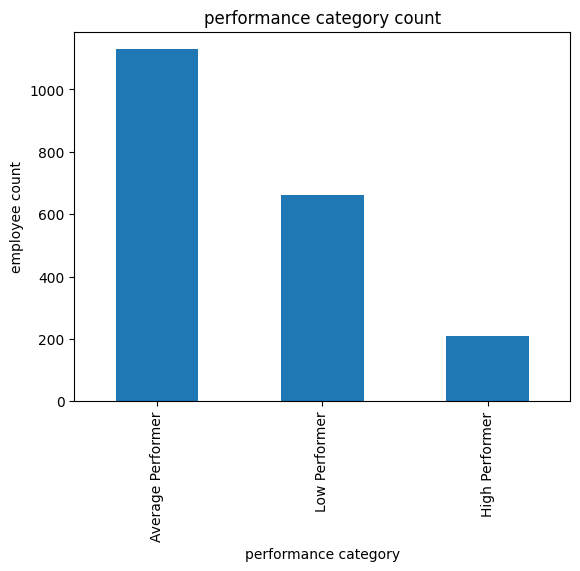

In [ ]:
# Count each performance category
train['Performance_Category'].value_counts().plot(kind='bar')
plt.title('performance category count')
plt.xlabel("performance category")
plt.ylabel("employee count")
plt.show()


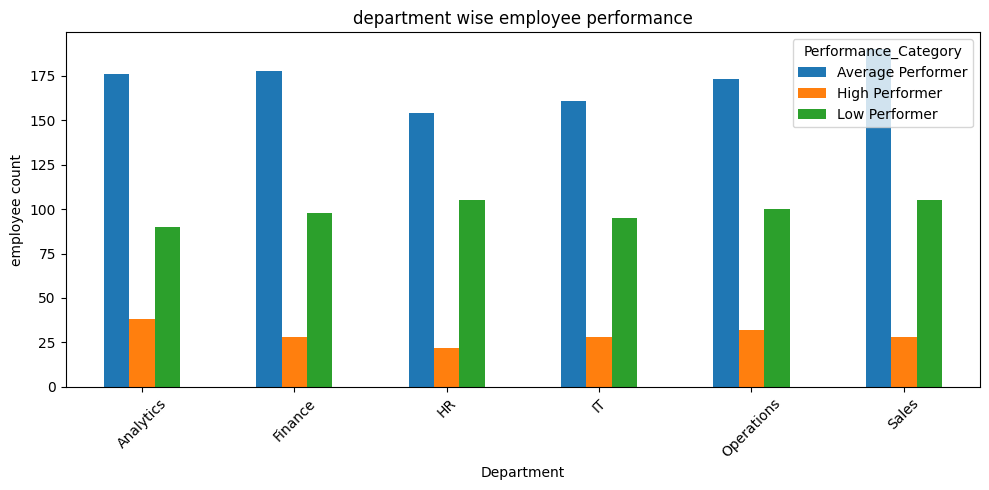

In [8]:
department_performance=pd.crosstab(train['Department'],train['Performance_Category'])
department_performance.plot(kind='bar',figsize=(10,5))
plt.title("department wise employee performance")
plt.xlabel("Department")
plt.ylabel("employee count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

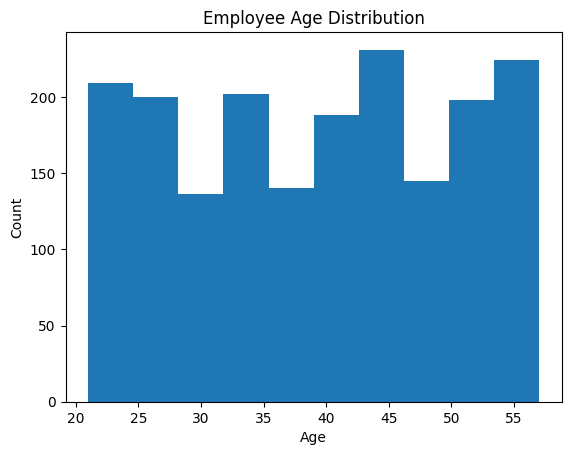

In [9]:
# Age distribution chart
train['Age'].plot(kind="hist")
plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

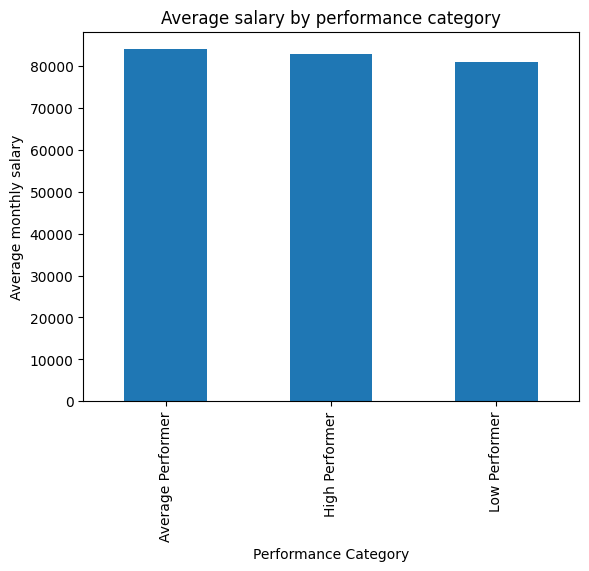

In [10]:
# Calculate average salary for each performance category
salary=train.groupby('Performance_Category')['Monthly_Salary'].mean()
salary.plot(kind="bar")
plt.title("Average salary by performance category")
plt.xlabel("Performance Category")
plt.ylabel("Average monthly salary")
plt.show()

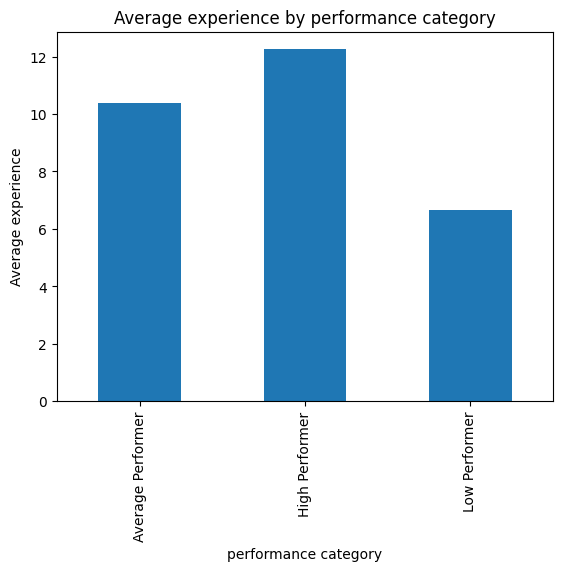

In [12]:
# Calculate average experience for each performance category
experience=train.groupby('Performance_Category')['Experience_Years'].mean()
experience.plot(kind="bar")
plt.title("Average experience by performance category")
plt.xlabel("performance category")
plt.ylabel("Average experience")
plt.show()


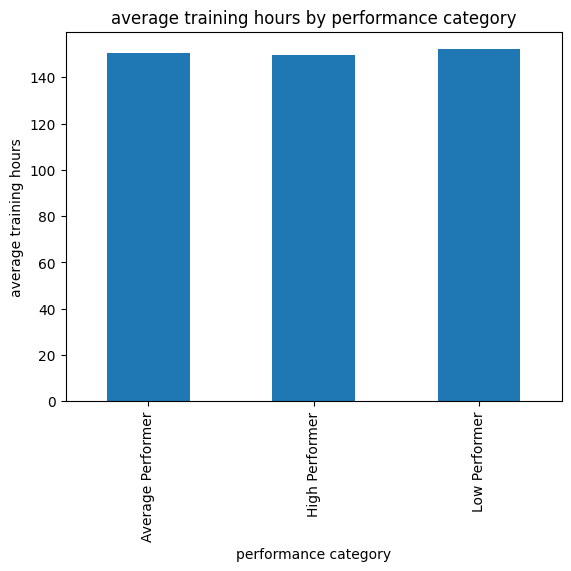

In [7]:
# Calculate average training hours for each performance category
training=train.groupby('Performance_Category')['Training_Hours'].mean()
training.plot(kind="bar")
plt.title("average training hours by performance category")
plt.xlabel("performance category")
plt.ylabel("average training hours")
plt.show()

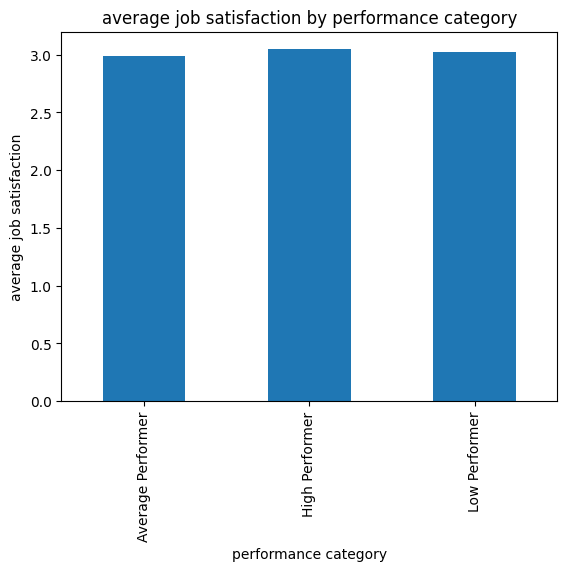

In [9]:
 #Calculate average job satisfaction for each performance category
 satisfaction=train.groupby('Performance_Category')['Job_Satisfaction'].mean()
 satisfaction.plot(kind="bar")
 plt.title("average job satisfaction by performance category")
 plt.xlabel("performance category")
 plt.ylabel("average job satisfaction")
 plt.show()

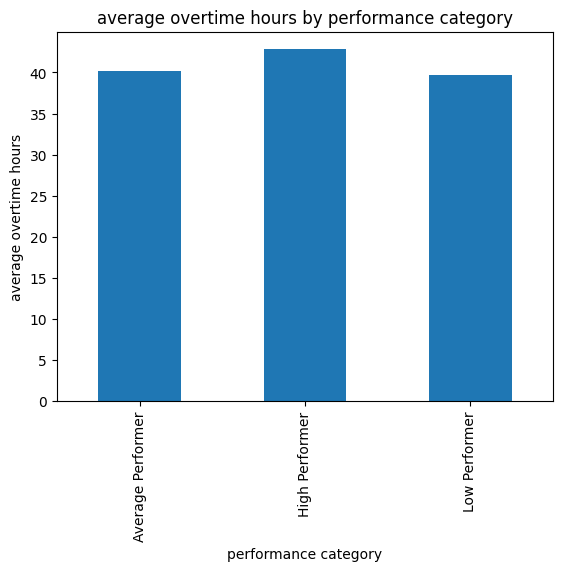

In [10]:
# Calculate average overtime hours for each performance category
overtime=train.groupby('Performance_Category')['Overtime_Hours'].mean()
overtime.plot(kind="bar")
plt.title("average overtime hours by performance category")
plt.xlabel("performance category")
plt.ylabel("average overtime hours")
plt.show()

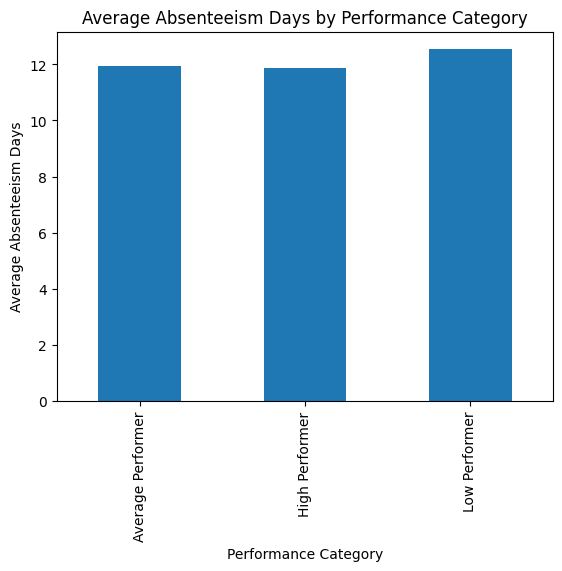

In [11]:
# Calculate average absenteeism days for each performance category
absenteeism = train.groupby('Performance_Category')['Absenteeism_Days'].mean()
absenteeism.plot(kind='bar')
plt.title('Average Absenteeism Days by Performance Category')
plt.xlabel('Performance Category')
plt.ylabel('Average Absenteeism Days')
plt.show()

In [12]:
# Display summary statistics
train.describe()

,Employee_ID,Age,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Last_Promotion_Years,Absenteeism_Days
count,2000.000000,1873.000000,1747.000000,1895.000000,1712.000000,1702.000000,1695.000000,1819.000000,1804.000000,1853.000000,1810.000000,1805.000000,1933.000000,1717.000000,1836.000000,1681.000000
mean,11000.500000,39.294180,9.351116,82924.088654,20.056659,150.835488,2.555162,3.055525,3.006098,3.490070,40.313260,92.309141,7.048629,2.935935,3.976852,12.127305
std,577.494589,10.853357,5.079696,38210.918035,11.279757,85.021787,1.697382,1.454743,1.402188,0.848336,23.266659,50.777598,4.325129,1.389050,2.313777,7.283737
min,10001.000000,21.000000,0.500000,18018.000000,1.000000,5.000000,0.000000,1.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.000000,0.000000,0.000000
25%,10500.750000,30.000000,5.000000,50205.500000,10.000000,80.000000,1.000000,2.000000,2.000000,2.800000,21.000000,48.000000,3.000000,2.000000,2.000000,6.000000
50%,11000.500000,40.000000,9.300000,81830.000000,20.000000,148.500000,3.000000,3.000000,3.000000,3.500000,41.000000,93.000000,7.000000,3.000000,4.000000,12.000000
75%,11500.250000,49.000000,13.800000,116175.500000,30.000000,224.000000,4.000000,4.000000,4.000000,4.200000,60.000000,136.000000,11.000000,4.000000,6.000000,18.000000
max,12000.000000,57.000000,18.000000,149960.000000,39.000000,299.000000,5.000000,5.000000,5.000000,5.000000,79.000000,179.000000,14.000000,5.000000,8.000000,24.000000


In [16]:
# Separate input features and target
x=train.drop(columns=['Performance_Category','Employee_ID'])
y=train['Performance_Category']
print("features shape:",x.shape)
print("target shape:",y.shape)

features shape: (2000, 20)
target shape: (2000,)


In [17]:
from sklearn.model_selection import train_test_split
# Import train_test_split to divide the dataset into training and validation sets
from sklearn.model_selection import train_test_split

# Split the input features (X) and target variable (y) into training and validation data
x_train, x_val, y_train, y_val = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=57,
    stratify=y
)

# Print the number of rows and columns in the training features
print("x_train:", x_train.shape)

# Print the number of rows and columns in the validation features
print("x_val:", x_val.shape)

# Print the shape of the training target values
print("y_train:", y_train.shape)

x_train: (1600, 20)
x_val: (400, 20)
y_train: (1600,)


In [18]:
# Display all input feature column names
print(x.columns.tolist())

# Display total number of input features
print("Total input features:", x.shape[1])

# Display target column name
print("Target column:", y.name)

['Age', 'Gender', 'City', 'Education_Level', 'Department', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Training_Hours', 'Certifications', 'Work_Life_Balance', 'Job_Satisfaction', 'Manager_Rating', 'Overtime_Hours', 'Commute_Time_Min', 'Laptop_Issue_Count', 'Cafeteria_Rating', 'Internet_Stability', 'Last_Promotion_Years', 'Absenteeism_Days']
Total input features: 20
Target column: Performance_Category


In [25]:
# Encode categorical input features
x_train=pd.get_dummies(x_train)
x_val=pd.get_dummies(x_val)
# Match validation columns with training columns
x_val = x_val.reindex(columns=x_train.columns, fill_value=0)

# Check the result
print(x_train.shape)
print(x_val.shape)

(1600, 39)
(400, 39)


In [20]:
train.head(10)

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,9.3,81830.0,15.0,20.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,Delhi,Graduate,Finance,12.7,55760.0,20.0,213.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,20.0,209.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,Delhi,Graduate,Sales,1.2,145192.0,5.0,117.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer
5,10006,43.0,Male,Kolkata,Diploma,HR,7.6,47024.0,26.0,182.0,...,5.0,2.7,36.0,94.0,3.0,2.0,Average,0.3,20.0,Average Performer
6,10007,40.0,Male,Bengaluru,Graduate,IT,16.9,41202.0,20.0,213.0,...,5.0,4.9,27.0,93.0,8.0,1.0,Average,3.6,12.0,Average Performer
7,10008,31.0,Female,Mumbai,Graduate,Finance,9.3,137414.0,16.0,128.0,...,3.0,2.1,31.0,127.0,13.0,3.0,Good,6.0,12.0,Low Performer
8,10009,44.0,Male,Bengaluru,Post Graduate,IT,10.8,69524.0,35.0,19.0,...,5.0,3.0,56.0,110.0,0.0,5.0,Poor,7.1,14.0,Average Performer
9,10010,56.0,Female,Hyderabad,Graduate,Operations,9.3,81830.0,38.0,49.0,...,3.0,2.8,40.0,161.0,6.0,4.0,Good,4.0,1.0,Average Performer


In [27]:
print("Employee_ID in X:", "Employee_ID" in x.columns)

Employee_ID in X: False


In [23]:
# Remove Employee_ID and separate input features
x = train.drop(columns=["Employee_ID", "Performance_Category"])

# Select target column
y = train["Performance_Category"]

# Check shapes
print("x:", x.shape)
print("y:", y.shape)

x: (2000, 20)
y: (2000,)


In [26]:
train.head(10)

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,9.3,81830.0,15.0,20.0,...,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,...,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,Delhi,Graduate,Finance,12.7,55760.0,20.0,213.0,...,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,20.0,209.0,...,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,Delhi,Graduate,Sales,1.2,145192.0,5.0,117.0,...,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer
5,10006,43.0,Male,Kolkata,Diploma,HR,7.6,47024.0,26.0,182.0,...,5.0,2.7,36.0,94.0,3.0,2.0,Average,0.3,20.0,Average Performer
6,10007,40.0,Male,Bengaluru,Graduate,IT,16.9,41202.0,20.0,213.0,...,5.0,4.9,27.0,93.0,8.0,1.0,Average,3.6,12.0,Average Performer
7,10008,31.0,Female,Mumbai,Graduate,Finance,9.3,137414.0,16.0,128.0,...,3.0,2.1,31.0,127.0,13.0,3.0,Good,6.0,12.0,Low Performer
8,10009,44.0,Male,Bengaluru,Post Graduate,IT,10.8,69524.0,35.0,19.0,...,5.0,3.0,56.0,110.0,0.0,5.0,Poor,7.1,14.0,Average Performer
9,10010,56.0,Female,Hyderabad,Graduate,Operations,9.3,81830.0,38.0,49.0,...,3.0,2.8,40.0,161.0,6.0,4.0,Good,4.0,1.0,Average Performer


In [28]:
x_train = pd.get_dummies(x_train)
x_val = pd.get_dummies(x_val)

x_val = x_val.reindex(columns=x_train.columns, fill_value=0)

In [29]:
print(x_train.head(5))
print(x_train.dtypes)

       Age  Experience_Years  Monthly_Salary  Projects_Completed  \
1208  33.0               7.9         60912.0                19.0   
1545  35.0               3.7         53765.0                18.0   
1814  45.0              10.6         48480.0                31.0   
1683  48.0              10.4         83524.0                28.0   
1826  42.0               7.6        119630.0                27.0   

      Training_Hours  Certifications  Work_Life_Balance  Job_Satisfaction  \
1208           148.5             3.0                1.0               4.0   
1545           250.0             3.0                3.0               2.0   
1814           148.5             5.0                3.0               5.0   
1683           148.5             3.0                2.0               5.0   
1826           177.0             0.0                5.0               1.0   

      Manager_Rating  Overtime_Hours  ...  Department_Analytics  \
1208             3.5            55.0  ...                  Tr

In [31]:
x_train.head(10)

,Age,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,...,Department_Analytics,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,Internet_Stability_Average,Internet_Stability_Excellent,Internet_Stability_Good,Internet_Stability_Poor
1208,33.0,7.9,60912.0,19.0,148.5,3.0,1.0,4.0,3.5,55.0,...,True,False,False,False,False,False,False,False,False,True
1545,35.0,3.7,53765.0,18.0,250.0,3.0,3.0,2.0,3.5,60.0,...,False,False,False,True,False,False,True,False,False,False
1814,45.0,10.6,48480.0,31.0,148.5,5.0,3.0,5.0,4.1,28.0,...,False,True,False,False,False,False,True,False,False,False
1683,48.0,10.4,83524.0,28.0,148.5,3.0,2.0,5.0,2.1,3.0,...,False,False,False,True,False,False,False,True,False,False
1826,42.0,7.6,119630.0,27.0,177.0,0.0,5.0,1.0,4.1,18.0,...,False,False,False,True,False,False,False,False,False,True
973,33.0,7.5,72909.0,39.0,20.0,4.0,2.0,1.0,3.5,20.0,...,False,False,True,False,False,False,True,False,False,False
1974,55.0,3.9,118290.0,18.0,183.0,5.0,1.0,4.0,4.1,72.0,...,False,False,False,False,True,False,True,False,False,False
1404,42.0,1.8,62350.0,20.0,293.0,3.0,1.0,4.0,4.3,29.0,...,False,False,False,False,False,True,True,False,False,False
300,40.0,5.7,81830.0,8.0,286.0,4.0,3.0,4.0,3.3,41.0,...,False,False,False,False,True,False,True,False,False,False
1051,40.0,4.2,63310.0,11.0,125.0,3.0,1.0,3.0,2.0,26.0,...,False,False,False,False,False,True,False,False,True,False


In [32]:
# Convert Boolean columns into 0 and 1
x_train = x_train.astype(int)
x_val = x_val.astype(int)

# Display first 5 rows
print(x_train.head())

      Age  Experience_Years  Monthly_Salary  Projects_Completed  \
1208   33                 7           60912                  19   
1545   35                 3           53765                  18   
1814   45                10           48480                  31   
1683   48                10           83524                  28   
1826   42                 7          119630                  27   

      Training_Hours  Certifications  Work_Life_Balance  Job_Satisfaction  \
1208             148               3                  1                 4   
1545             250               3                  3                 2   
1814             148               5                  3                 5   
1683             148               3                  2                 5   
1826             177               0                  5                 1   

      Manager_Rating  Overtime_Hours  ...  Department_Analytics  \
1208               3              55  ...                     1   


In [33]:
x_train.head(10)

,Age,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,...,Department_Analytics,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,Internet_Stability_Average,Internet_Stability_Excellent,Internet_Stability_Good,Internet_Stability_Poor
1208,33,7,60912,19,148,3,1,4,3,55,...,1,0,0,0,0,0,0,0,0,1
1545,35,3,53765,18,250,3,3,2,3,60,...,0,0,0,1,0,0,1,0,0,0
1814,45,10,48480,31,148,5,3,5,4,28,...,0,1,0,0,0,0,1,0,0,0
1683,48,10,83524,28,148,3,2,5,2,3,...,0,0,0,1,0,0,0,1,0,0
1826,42,7,119630,27,177,0,5,1,4,18,...,0,0,0,1,0,0,0,0,0,1
973,33,7,72909,39,20,4,2,1,3,20,...,0,0,1,0,0,0,1,0,0,0
1974,55,3,118290,18,183,5,1,4,4,72,...,0,0,0,0,1,0,1,0,0,0
1404,42,1,62350,20,293,3,1,4,4,29,...,0,0,0,0,0,1,1,0,0,0
300,40,5,81830,8,286,4,3,4,3,41,...,0,0,0,0,1,0,1,0,0,0
1051,40,4,63310,11,125,3,1,3,2,26,...,0,0,0,0,0,1,0,0,1,0


In [34]:
from sklearn.ensemble import RandomForestClassifier
# Create the model
model=RandomForestClassifier(n_estimators=100,random_state=57)
#train the model
model.fit(x_train,y_train)


RandomForestClassifier(random_state=57)

In [35]:
# Predict performance categories
y_pred=model.predict(x_val)
print("predictions:")
print(y_pred[:10])

predictions:
['Average Performer' 'Low Performer' 'Average Performer'
 'Average Performer' 'Average Performer' 'Average Performer'
 'Average Performer' 'Average Performer' 'Average Performer'
 'High Performer']


In [36]:
from sklearn.metrics import accuracy_score,classification_report
accuracy=accuracy_score(y_val,y_pred)
print("Model Accuracy:", accuracy * 100, "%")

# Display performance report
print("\nClassification Report:")
print(classification_report(y_val, y_pred))


Model Accuracy: 84.5 %

Classification Report:
                   precision    recall  f1-score   support

Average Performer       0.80      0.98      0.88       226
   High Performer       0.86      0.29      0.44        41
    Low Performer       0.95      0.79      0.86       133

         accuracy                           0.84       400
        macro avg       0.87      0.69      0.73       400
     weighted avg       0.86      0.84      0.83       400



In [39]:
from google.colab import files

uploaded = files.upload()


Saving perf_test.csv to perf_test.csv


In [40]:
#load the test dataset
test = pd.read_csv('/content/perf_test.csv')

# Display first 10 rows
test.head(10)

,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,...,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days
0,12001,43.0,Female,Delhi,Graduate,Operations,NaN,110905.0,23.0,225.0,...,NaN,2.0,2.9,64.0,45.0,2.0,1.0,Excellent,3.3,1.0
1,12002,39.0,Male,Hyderabad,Post Graduate,HR,17.5,20977.0,26.0,86.0,...,3.0,5.0,2.8,65.0,80.0,4.0,4.0,Average,4.3,0.0
2,12003,NaN,Male,Delhi,Graduate,Finance,NaN,133650.0,NaN,246.0,...,1.0,NaN,NaN,25.0,111.0,6.0,2.0,Average,1.9,4.0
3,12004,25.0,NaN,Hyderabad,Graduate,Sales,14.1,72641.0,7.0,NaN,...,5.0,3.0,4.9,30.0,134.0,9.0,2.0,Average,4.1,23.0
4,12005,39.0,Male,NaN,Post Graduate,Analytics,NaN,132465.0,10.0,56.0,...,2.0,3.0,4.3,50.0,99.0,1.0,4.0,Poor,7.1,2.0
5,12006,54.0,Male,Delhi,Graduate,IT,9.9,72431.0,5.0,43.0,...,2.0,1.0,3.6,40.0,32.0,12.0,NaN,NaN,6.9,6.0
6,12007,30.0,Female,Delhi,Graduate,Operations,14.5,34756.0,12.0,263.0,...,4.0,3.0,3.3,50.0,148.0,12.0,NaN,Excellent,7.5,5.0
7,12008,45.0,Male,Delhi,Post Graduate,HR,10.9,27796.0,32.0,275.0,...,4.0,1.0,3.6,18.0,63.0,5.0,4.0,Excellent,3.9,NaN
8,12009,22.0,Male,Kolkata,NaN,Analytics,6.0,122583.0,31.0,76.0,...,2.0,4.0,3.4,72.0,133.0,3.0,4.0,NaN,3.3,22.0
9,12010,31.0,Female,Pune,Post Graduate,IT,10.3,99014.0,22.0,74.0,...,4.0,1.0,3.5,2.0,NaN,1.0,5.0,Excellent,5.3,18.0


In [41]:
# Check number of rows and columns
test.shape

(500, 21)

In [42]:
#check column names
test.columns.tolist()

['Employee_ID',
 'Age',
 'Gender',
 'City',
 'Education_Level',
 'Department',
 'Experience_Years',
 'Monthly_Salary',
 'Projects_Completed',
 'Training_Hours',
 'Certifications',
 'Work_Life_Balance',
 'Job_Satisfaction',
 'Manager_Rating',
 'Overtime_Hours',
 'Commute_Time_Min',
 'Laptop_Issue_Count',
 'Cafeteria_Rating',
 'Internet_Stability',
 'Last_Promotion_Years',
 'Absenteeism_Days']

In [43]:
#check missing values
test.isnull().sum()

,0
Employee_ID,0
Age,33
Gender,21
City,46
Education_Level,49
Department,49
Experience_Years,70
Monthly_Salary,24
Projects_Completed,82
Training_Hours,68


In [45]:
#check datatypes
test.dtypes

,0
Employee_ID,int64
Age,float64
Gender,object
City,object
Education_Level,object
Department,object
Experience_Years,float64
Monthly_Salary,float64
Projects_Completed,float64
Training_Hours,float64


In [48]:
# Fill missing values in numerical columns using the median
for col in test.select_dtypes(include=['int64','float64']).columns:
        if col !='Employee_ID':
                test[col]=train[col].fillna(test[col].median())
# Fill missing values in categorical columns using the mode
for col in test.select_dtypes(include=['object']).columns:
       if col !='Performance_Category':
        test[col]=test[col].fillna(test[col].mode()[0])

In [49]:
test.isnull().sum()

,0
Employee_ID,0
Age,0
Gender,0
City,0
Education_Level,0
Department,0
Experience_Years,0
Monthly_Salary,0
Projects_Completed,0
Training_Hours,0


In [50]:
# Save employee IDs separately
test_ids=test["Employee_ID"].copy()
x_test=test.drop(columns=["Employee_ID"])
print("\nTest input shape:", x_test.shape)
print("Number of Employee IDs:", len(test_ids))


Test input shape: (500, 20)
Number of Employee IDs: 500


In [51]:
# Convert categorical columns into numerical columns
x_test=pd.get_dummies(x_test)
# Match the training columns
x_test = x_test.reindex(
    columns=x_train.columns,
    fill_value=0
)

# Convert Boolean columns to 0 and 1
bool_cols = x_test.select_dtypes(include="bool").columns
x_test[bool_cols] = x_test[bool_cols].astype(int)

print("Encoded test shape:", x_test.shape)
print(x_test.head())

Encoded test shape: (500, 39)
    Age  Experience_Years  Monthly_Salary  Projects_Completed  Training_Hours  \
0  49.0               9.3         81830.0                15.0            20.0   
1  35.0               0.8        129555.0                15.0           163.0   
2  28.0              12.7         55760.0                20.0           213.0   
3  41.0               4.9        128174.0                20.0           209.0   
4  39.0               1.2        145192.0                 5.0           117.0   

   Certifications  Work_Life_Balance  Job_Satisfaction  Manager_Rating  \
0             1.0                2.0               3.0             3.2   
1             0.0                5.0               4.0             2.3   
2             1.0                3.0               1.0             4.2   
3             5.0                1.0               2.0             4.5   
4             0.0                3.0               3.0             4.2   

   Overtime_Hours  ...  Department_Ana

In [53]:
x_test.head(5)

,Age,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,...,Department_Analytics,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,Internet_Stability_Average,Internet_Stability_Excellent,Internet_Stability_Good,Internet_Stability_Poor
0,49.0,9.3,81830.0,15.0,20.0,1.0,2.0,3.0,3.2,43.0,...,0,0,0,0,1,0,0,1,0,0
1,35.0,0.8,129555.0,15.0,163.0,0.0,5.0,4.0,2.3,43.0,...,0,0,1,0,0,0,1,0,0,0
2,28.0,12.7,55760.0,20.0,213.0,1.0,3.0,1.0,4.2,50.0,...,0,1,0,0,0,0,1,0,0,0
3,41.0,4.9,128174.0,20.0,209.0,5.0,1.0,2.0,4.5,78.0,...,0,0,0,0,0,1,1,0,0,0
4,39.0,1.2,145192.0,5.0,117.0,0.0,3.0,3.0,4.2,20.0,...,1,0,0,0,0,0,0,0,0,1


In [54]:
# Predict performance categories for test data
test_predictions=model.predict(x_test)
#display first 10 predictions
print(test_predictions[:10])
# Check total predictions
print(len(test_predictions))

['Average Performer' 'Low Performer' 'Average Performer'
 'Average Performer' 'Low Performer' 'Average Performer'
 'Average Performer' 'Average Performer' 'Average Performer'
 'Average Performer']
500


In [55]:
# Create a DataFrame with employee IDs and predicted categories
submission = pd.DataFrame({
    "Employee_ID": test_ids,
    "Predicted_Performance_Category": test_predictions
})

# Display first 10 predictions
print(submission.head(10))

# Check the number of rows and columns
print("Final shape:", submission.shape)

# Save predictions as a CSV file
submission.to_csv("Employee_Performance_Predictions.csv", index=False)


   Employee_ID Predicted_Performance_Category
0        12001              Average Performer
1        12002                  Low Performer
2        12003              Average Performer
3        12004              Average Performer
4        12005                  Low Performer
5        12006              Average Performer
6        12007              Average Performer
7        12008              Average Performer
8        12009              Average Performer
9        12010              Average Performer
Final shape: (500, 2)


In [57]:
print(submission["Predicted_Performance_Category"].value_counts())

print("\nPercentage distribution:")
print(
    submission["Predicted_Performance_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Predicted_Performance_Category
Average Performer    330
Low Performer        132
High Performer        38
Name: count, dtype: int64

Percentage distribution:
Predicted_Performance_Category
Average Performer    66.0
Low Performer        26.4
High Performer        7.6
Name: proportion, dtype: float64


In [56]:
from google.colab import files

files.download("Employee_Performance_Predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
# Get feature importance from the trained model
importance = model.feature_importances_

# Create a table of features and their importance
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": importance
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
print(feature_importance.head(10))

               Feature  Importance
3   Projects_Completed    0.258748
1     Experience_Years    0.200867
2       Monthly_Salary    0.045254
8       Manager_Rating    0.044335
10    Commute_Time_Min    0.041295
4       Training_Hours    0.039803
9       Overtime_Hours    0.038744
0                  Age    0.035744
14    Absenteeism_Days    0.032063
11  Laptop_Issue_Count    0.031602


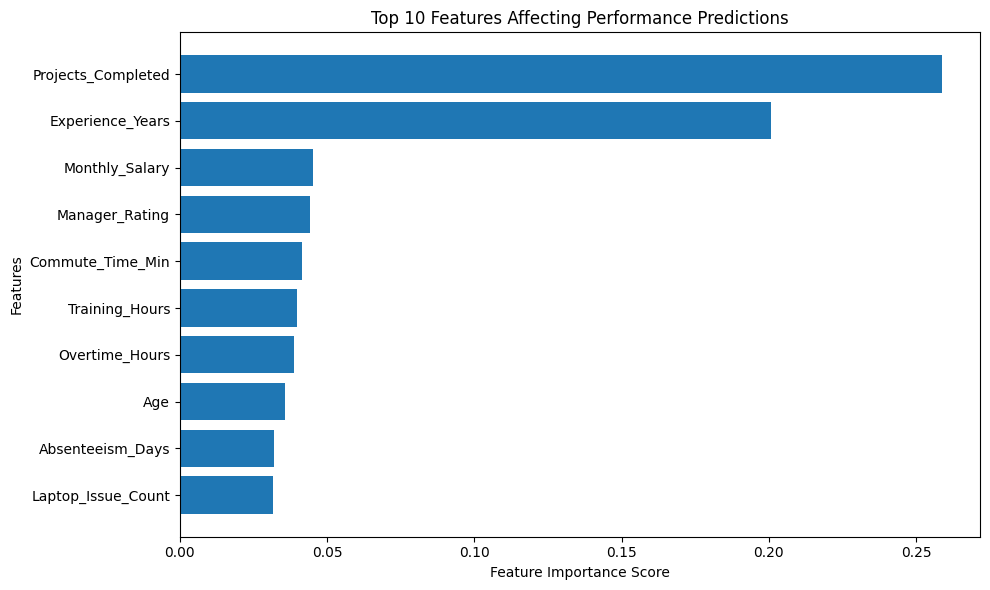

In [59]:
# Select top 10 important features
top_features = feature_importance.head(10)

# Create a bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

# Show the most important feature at the top
plt.gca().invert_yaxis()

plt.title("Top 10 Features Affecting Performance Predictions")
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()